# LeJEPA: self-supervised learning without the heuristics

[LeJEPA](https://arxiv.org/abs/2511.08544) ([code](https://github.com/galilai-group/lejepa)) uses no teacher network, stop-gradient or schedule. Every view's embedding predicts the mean embedding of the global views. **SIGReg** (Sketched Isotropic Gaussian Regularization) prevents collapse by pushing random 1D projections of the embeddings toward a standard normal.

In [1]:
import torch
import torch.nn.functional as F
from torch import nn

from torch_world import metrics, plots
from torch_world.envs import PointMass
from torch_world.models import LeJEPA
from torch_world.nn import MLP, CLSEncoder
from torch_world.utils import recompute_batchnorm

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Views
Two global crops (30-100% of the image) and four local crops (5-30%) per image.

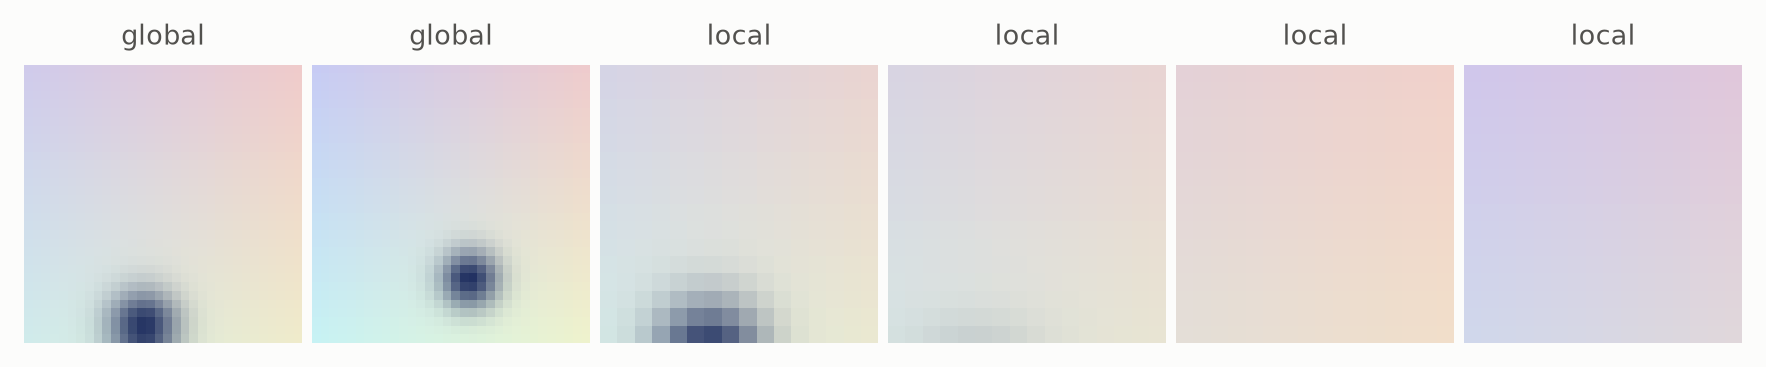

In [2]:
def crop(images, scale, size):
    s = torch.empty(1).uniform_(*scale).sqrt().item()
    n = max(2, int(images.size(-1) * s))
    i, j = torch.randint(0, images.size(-1) - n + 1, (2,)).tolist()
    return F.interpolate(images[..., i : i + n, j : j + n], size=size, mode="bilinear", antialias=True)


def views(images):
    return [crop(images, (0.3, 1.0), 32) for _ in range(2)] + [crop(images, (0.05, 0.3), 16) for _ in range(4)]


env = PointMass(batch_size=256, size=32, device=device)
images = env.reset()
plots.images(torch.stack([F.interpolate(v[:1], size=32)[0] for v in views(images)]), ["global", "global"] + ["local"] * 4, ncols=6)

## Train

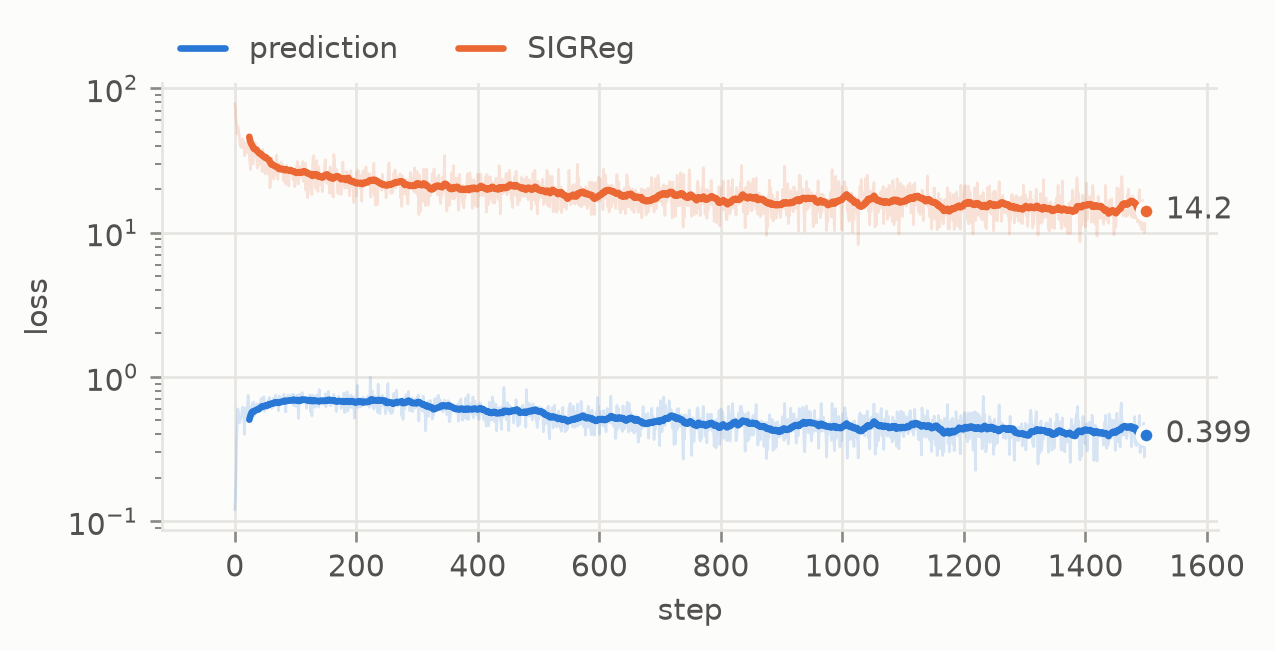

In [3]:
model = LeJEPA(CLSEncoder(32, 4, embed_dim=192, depth=6, num_heads=6, resize=True), MLP([192, 512, 512, 64], norm=nn.BatchNorm1d), lamb=0.05).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=5e-2)

log = {"prediction": [], "SIGReg": []}
for step in range(1500):
    out = model(views(env.reset()), num_global=2)
    opt.zero_grad()
    out["loss"].backward()
    opt.step()
    log["prediction"].append(out["pred_loss"].item())
    log["SIGReg"].append(out["sigreg_loss"].item())

plots.curves(log)

## The embeddings are isotropic Gaussian
Project the embeddings of fresh images on random unit directions. Under SIGReg every projection should match a standard normal.

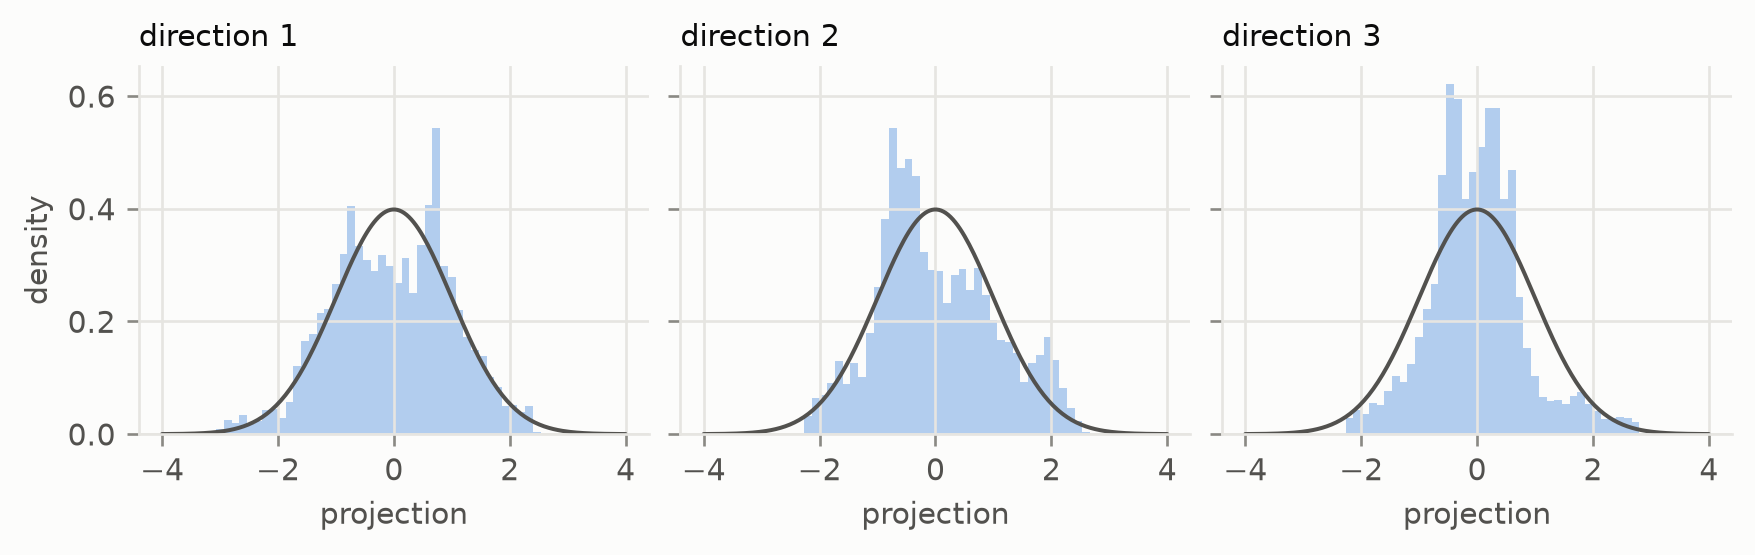

In [4]:
recompute_batchnorm(model, [PointMass(batch_size=256, size=32, device=device).reset() for _ in range(16)], lambda x: model.projector(model.encoder(x)))
model.eval()
with torch.no_grad():
    z = model.projector(model.encoder(PointMass(batch_size=4096, size=32, device=device).reset()))
directions = F.normalize(torch.randn(z.size(1), 3, device=device), dim=0)
projections = (z @ directions).cpu()

with plots.style() as plt:
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.2), sharey=True, layout="constrained")
    grid = torch.linspace(-4, 4, 200)
    for i, ax in enumerate(axes):
        ax.hist(projections[:, i], bins=60, range=(-4, 4), density=True, color=plots.SERIES[0], alpha=0.35, lw=0)
        ax.plot(grid, torch.exp(-grid**2 / 2) / (2 * torch.pi) ** 0.5, color=plots.INK_2, lw=1.2)
        ax.set(title=f"direction {i + 1}", xlabel="projection")
    axes[0].set_ylabel("density")
    plt.close(fig)
fig

## How good are the embeddings?
LeJEPA is evaluated on the frozen backbone (the encoder before the projector). Three metrics on 2048 fresh images, against the same encoder at random initialization:
- **linear probe**: regresses the position of the point, fit on 1536 images and scored by R² on 512;
- **RankMe**: the effective rank of the embeddings, out of 192 dimensions;
- **LiDAR**: the effective rank of the embeddings after whitening by their spread across 4 global crops of the same image, so only directions that tell images apart count. It was designed to predict linear-probe quality in JEPAs.

In [5]:
env = PointMass(batch_size=2048, size=32, device=device)
images = env.reset(generator=torch.Generator().manual_seed(7))
position = env.state

baseline = CLSEncoder(32, 4, embed_dim=192, depth=6, num_heads=6, resize=True).to(device).eval()
print(f"{'':12s}{'linear probe R²':>17s}{'RankMe':>9s}{'LiDAR':>8s}")
for name, net in {"random init": baseline, "LeJEPA": model.encoder}.items():
    with torch.no_grad():
        z = net(images)
        crops = torch.stack([net(crop(images, (0.3, 1.0), 32)) for _ in range(4)], 1)
    linear = metrics.linear_probe(z[:1536], position[:1536], z[1536:], position[1536:])
    print(f"{name:12s}{linear.score:17.3f}{metrics.rankme(z):9.1f}{metrics.lidar(crops):8.1f}")

              linear probe R²   RankMe   LiDAR


random init             0.993      1.1     6.3


LeJEPA                  0.993      1.8    10.5
